# Homework 5 - question 1d #

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

eta = 4
tau_E = 5
w_EI = 10
w_IE = 10
E_bar = 0.1
I_bar = 0.1

def simulate(tau_I, eps, t_end=1000, dt=0.02):
    # Critical self-coupling at the Hopf bifurcation
    w_EE_hopf = (1 + tau_E / tau_I) / (
        eta * E_bar * (1 - E_bar)
    )
    w_EE = (1 + eps) * w_EE_hopf

    # Adjust p_E and p_I to keep the equilibrium fixed
    p_E = (
        np.log(E_bar / (1 - E_bar)) / eta
        - w_EE * E_bar + w_EI * I_bar
    )
    p_I = (
        np.log(I_bar / (1 - I_bar)) / eta
        - w_IE * E_bar
    )

    def sigmoid(x):
        # Numerically stable logistic function
        return 1 / (1 + np.exp(-np.clip(eta * x, -500, 500)))

    def wc(t, y):
        E, I = y
        dE = (
            -E + sigmoid(w_EE * E - w_EI * I + p_E)
        ) / tau_E
        dI = (
            -I + sigmoid(w_IE * E + p_I)
        ) / tau_I
        return [dE, dI]

    t_eval = np.arange(0, t_end, dt)
    y0 = [E_bar + 1e-4, I_bar]

    sol = solve_ivp(
        wc, (0, t_end), y0,
        t_eval=t_eval, rtol=1e-8, atol=1e-10
    )

    t = sol.t
    E, I = sol.y

    # Discard the initial transient
    keep = t > 0.5 * t_end
    ts, Es, Is = t[keep], E[keep], I[keep]

    peaks_E, _ = find_peaks(Es, prominence=1e-7)
    peaks_I, _ = find_peaks(Is, prominence=1e-7)

    if len(peaks_E) < 3 or len(peaks_I) < 3:
        return {
            "tau_I": tau_I, "eps": eps,
            "amplitude": np.ptp(Es),
            "period": np.nan, "frequency": np.nan,
            "lag_deg": np.nan,
            "t": t, "E": E, "I": I
        }

    peak_times_E = ts[peaks_E]
    peak_times_I = ts[peaks_I]

    # Average period from successive E peaks
    period = np.mean(np.diff(peak_times_E))

    # Find the first I peak following each E peak
    lags = []
    for te in peak_times_E[:-1]:
        candidates = peak_times_I[
            (peak_times_I > te) &
            (peak_times_I < te + period)
        ]
        if len(candidates):
            lags.append(candidates[0] - te)

    lag_deg = (
        360 * np.mean(lags) / period if lags else np.nan
    )

    return {
        "tau_I": tau_I, "eps": eps,
        "amplitude": np.ptp(Es),
        "period": period,
        "frequency": 1000 / period,
        "lag_deg": lag_deg,
        "t": t, "E": E, "I": I
    }

In [4]:
eps_values = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2]
results = [
    simulate(tau_I=10, eps=eps)
    for eps in eps_values
]

print(" eps      amplitude       period (ms)    freq (Hz)    lag (deg)")
for r in results:
    print(
        f"{r['eps']:6.3f}  {r['amplitude']:12.6g}  "
        f"{r['period']:12.5g}  {r['frequency']:10.4f}  "
        f"{r['lag_deg']:10.3f}"
    )

 eps      amplitude       period (ms)    freq (Hz)    lag (deg)
 0.005   0.000428844         12.59     79.4265      78.522
 0.010   0.000903008        12.594     79.4039      78.324
 0.020    0.00399243        12.603     79.3489      77.830
 0.050     0.0608653        13.106     76.3012      68.374
 0.100     0.0873855         14.81     67.5206      56.585
 0.200      0.123149        17.084     58.5358      49.732


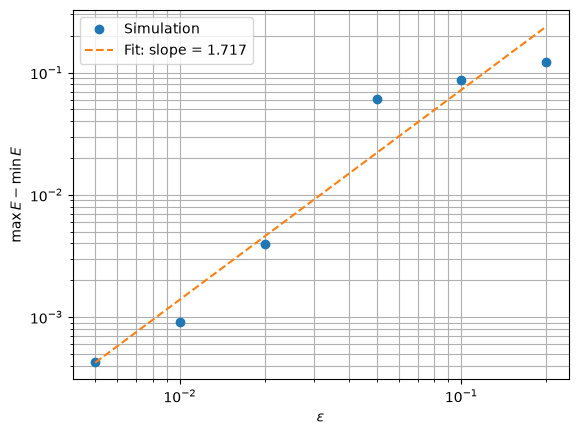

In [6]:
# Plot amplitude versus epsilon on log-log axes
eps_arr = np.array([r["eps"] for r in results])
amp_arr = np.array([r["amplitude"] for r in results])

valid = np.isfinite(amp_arr) & (amp_arr > 0)
slope, intercept = np.polyfit(
    np.log(eps_arr[valid]), np.log(amp_arr[valid]), 1
)

plt.figure()
plt.loglog(eps_arr, amp_arr, "o", label="Simulation")
plt.loglog(
    eps_arr[valid],
    np.exp(intercept) * eps_arr[valid]**slope,
    "--", label=f"Fit: slope = {slope:.3f}"
)
plt.xlabel(r"$\epsilon$")
plt.ylabel(r"$\max E-\min E$")
plt.legend()
plt.grid(True, which="both")
plt.show()

In [14]:
#part 2
taui_values = [2,3,5,7.5,10,15,20]
results = [
    simulate(tau_I=t_i, eps=0.02)
    for t_i in taui_values
]

print(" tau      amplitude       period (ms)    freq (Hz)    lag (deg)")
for r in results:
    print(
        f"{r['tau_I']:6.3f}  {r['amplitude']:12.6g}  "
        f"{r['period']:12.5g}  {r['frequency']:10.4f}  "
        f"{r['lag_deg']:10.3f}"
    )

 tau      amplitude       period (ms)    freq (Hz)    lag (deg)
 2.000     0.0290519        6.2831    159.1577      60.264
 3.000     0.0256064        7.3026    136.9366      66.551
 5.000     0.0106205        9.1056    109.8231      72.527
 7.500    0.00555315         10.99     90.9880      75.949
10.000    0.00399243        12.603     79.3489      77.830
15.000    0.00285771        15.331     65.2289      79.928
20.000    0.00241443        17.642     56.6822      81.199


In [30]:
f_sim = []
for r in results:
    f_sim.append(r['frequency'])

In [32]:
f_sim

[np.float64(159.15768854064643),
 np.float64(136.93664666317613),
 np.float64(109.82306284319706),
 np.float64(90.9880474792175),
 np.float64(79.34893184130213),
 np.float64(65.22891271556118),
 np.float64(56.682201788638366)]

In [26]:
tau_i_arr = np.array(taui_values)
w_arr = np.sqrt(2.592/tau_i_arr - 1/(tau_i_arr)**2)

In [34]:
f_theory = list(1000*w_arr/(2*np.pi))
f_theory

[np.float64(162.77435154984133),
 np.float64(138.0974233769287),
 np.float64(110.08184938319123),
 np.float64(91.12537459431516),
 np.float64(79.45004556900923),
 np.float64(65.3031089643752),
 np.float64(56.74046713092238)]

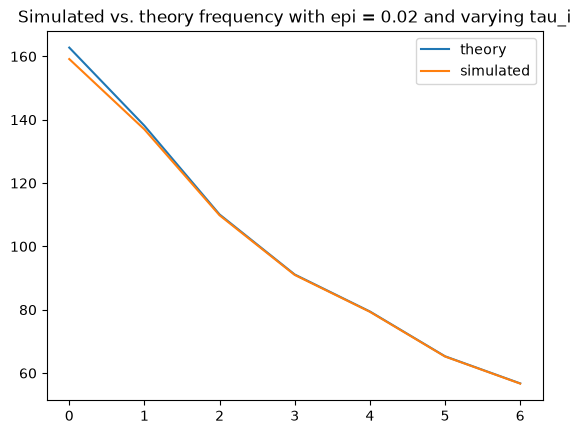

In [40]:
plt.plot(range(len(f_sim)),f_theory, label = 'theory')
plt.plot(range(len(f_sim)),f_sim,label = 'simulated')
plt.legend()
plt.title('Simulated vs. theory frequency with epi = 0.02 and varying tau_i')
plt.show()

The simulated and theoritical values for the frequency are quite similar. They differ more with smaller values of tau_i.

In [45]:
#part 3

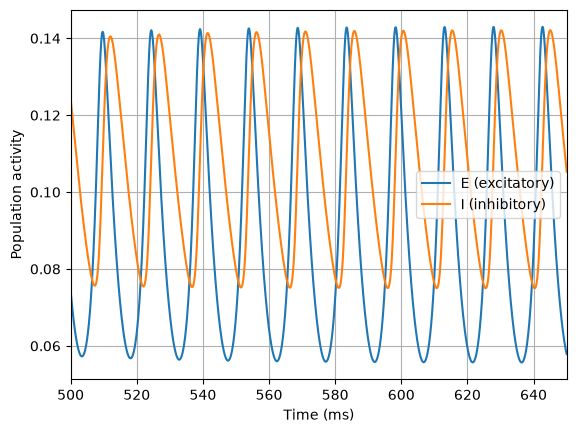

In [64]:
r = simulate(tau_I=10, eps=0.1, t_end=1000)

plt.figure()
plt.plot(r["t"], r["E"], label="E (excitatory)")
plt.plot(r["t"], r["I"], label="I (inhibitory)")
plt.xlim(500, 650)
plt.xlabel("Time (ms)")
plt.ylabel("Population activity")
plt.legend()
plt.grid(True)
plt.show()

* As episilon grows, the period increases a lot. The lag gets smaller. The oscillation frequency shifts away from angular frequency as the trajectory moves further from the equilibrium. Because of this, the period increases. The lag gets smaller because it has the opposite relationship to angular frequency as the period does. In other words, increasing episilon moves the system farther from the Hopf bifurcation, making nonlinear effects from f(x) more important.
* The Hopf bifurcation is supercritical because stable oscillations emerge continuously for positive episilon.
    * Characteristics of supercritical Hopf bifurcation: at the critical parameter the equilibrium has a pair of purely imaginary eigenvalues, as the parameter passes through the bifurcation the equilibrium becomes unstable, and a stable, small-amplitude limit cycle emerges on the unstable-equilibrium side.